<a href="https://colab.research.google.com/github/mloulaps-rgb/---/blob/main/HCI_%D0%9B%D0%A01_%D0%90%D0%BD%D0%B0%D0%BB%D1%96%D0%B7_%D1%82%D0%BE%D0%BD%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D1%81%D1%82%D1%96_%D0%92%D0%B5%D0%BB%D0%B8%D1%87%D0%BA%D0%BE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Лабораторна робота №1. Аналіз тональності текстів логістичною регресією
# Крок 1-2. Завантаження бібліотек і набору даних twitter_samples (nltk),
#           поділ на тренувальну та тестову вибірки.
import nltk
import numpy as np
import re
import string
from nltk.corpus import twitter_samples, stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import TweetTokenizer

nltk.download('twitter_samples')
nltk.download('stopwords')

all_positive_tweets = twitter_samples.strings('positive_tweets.json')
all_negative_tweets = twitter_samples.strings('negative_tweets.json')
print("Усього позитивних твітів:", len(all_positive_tweets))
print("Усього негативних твітів:", len(all_negative_tweets))

# Поділ 80/20: по 4000 на навчання і по 1000 на тест для кожного класу
test_pos  = all_positive_tweets[4000:]
train_pos = all_positive_tweets[:4000]
test_neg  = all_negative_tweets[4000:]
train_neg = all_negative_tweets[:4000]

train_x = train_pos + train_neg
test_x  = test_pos + test_neg

# Мітки: 1 - позитивний клас, 0 - негативний
train_y = np.append(np.ones(len(train_pos)), np.zeros(len(train_neg)))
test_y  = np.append(np.ones(len(test_pos)),  np.zeros(len(test_neg)))

print("Розмір train_x:", len(train_x), " test_x:", len(test_x))
print("Форма train_y:", train_y.shape, " test_y:", test_y.shape)

[nltk_data] Downloading package twitter_samples to /root/nltk_data...
[nltk_data]   Unzipping corpora/twitter_samples.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Усього позитивних твітів: 5000
Усього негативних твітів: 5000
Розмір train_x: 8000  test_x: 2000
Форма train_y: (8000,)  test_y: (2000,)


In [2]:
# Крок 3. Попередня обробка тексту: токенізація, видалення стоп-слів,
#         пунктуації, посилань, стемінг (PorterStemmer).
def process_tweet(tweet):
    """Очищує твіт і повертає список оброблених слів."""
    stemmer = PorterStemmer()
    stopwords_english = stopwords.words('english')
    tweet = re.sub(r'\$\w*', '', tweet)
    tweet = re.sub(r'^RT[\s]+', '', tweet)
    tweet = re.sub(r'https?://[^\s\n\r]+', '', tweet)
    tweet = re.sub(r'#', '', tweet)
    tokenizer = TweetTokenizer(preserve_case=False, strip_handles=True, reduce_len=True)
    tweet_tokens = tokenizer.tokenize(tweet)
    tweets_clean = []
    for word in tweet_tokens:
        if (word not in stopwords_english and
                word not in string.punctuation):
            stem_word = stemmer.stem(word)
            tweets_clean.append(stem_word)
    return tweets_clean

demo = train_x[0]
print("Початковий твіт:\n", demo)
print("\nПісля обробки:\n", process_tweet(demo))

Початковий твіт:
 #FollowFriday @France_Inte @PKuchly57 @Milipol_Paris for being top engaged members in my community this week :)

Після обробки:
 ['followfriday', 'top', 'engag', 'member', 'commun', 'week', ':)']


In [3]:
# Крок 4. Побудова словника частот слів для позитивного і негативного класів.
def build_freqs(tweets, ys):
    """Будує словник: (слово, мітка) -> кількість появ."""
    yslist = np.squeeze(ys).tolist()
    freqs = {}
    for y, tweet in zip(yslist, tweets):
        for word in process_tweet(tweet):
            pair = (word, y)
            freqs[pair] = freqs.get(pair, 0) + 1
    return freqs

freqs = build_freqs(train_x, train_y)
print("Тип freqs:", type(freqs))
print("Кількість унікальних пар (слово, клас):", len(freqs))

for word in ['happi', 'sad', 'love', 'hate', 'good', 'bad', ':)', ':(']:
    pos = freqs.get((word, 1.0), 0)
    neg = freqs.get((word, 0.0), 0)
    print(f"  {word!r:10} -> позитив: {pos:5d}   негатив: {neg:5d}")

Тип freqs: <class 'dict'>
Кількість унікальних пар (слово, клас): 11397
  'happi'    -> позитив:   162   негатив:    18
  'sad'      -> позитив:     5   негатив:   100
  'love'     -> позитив:   336   негатив:   128
  'hate'     -> позитив:     9   негатив:    45
  'good'     -> позитив:   191   негатив:    83
  'bad'      -> позитив:    14   негатив:    54
  ':)'       -> позитив:  2960   негатив:     2
  ':('       -> позитив:     1   негатив:  3675


In [6]:
# Крок 5. Логістична регресія: сигмоїда та навчання градієнтним спуском.
def sigmoid(z):
    """Логістична сигмоїда."""
    return 1.0 / (1.0 + np.exp(-z))

def gradientDescent(x, y, theta, alpha, num_iters):
    """Навчання методом градієнтного спуску."""
    m = x.shape[0]
    for i in range(num_iters):
        h = sigmoid(np.dot(x, theta))
        J = -1.0/m * (np.dot(y.T, np.log(h)) +
                      np.dot((1 - y).T, np.log(1 - h)))
        theta = theta - (alpha/m) * np.dot(x.T, (h - y))
    return float(J.item()), theta

print("sigmoid(0) =", sigmoid(0))
print("sigmoid(4.92) =", round(sigmoid(4.92), 4))

sigmoid(0) = 0.5
sigmoid(4.92) = 0.9928


In [8]:
# Крок 5 (продовження). Виділення ознак і навчання моделі.
def extract_features(tweet, freqs):
    """Для твіта повертає вектор [1, сума_позитивних, сума_негативних]."""
    words = process_tweet(tweet)
    x = np.zeros(3)
    x[0] = 1
    for word in words:
        x[1] += freqs.get((word, 1.0), 0)
        x[2] += freqs.get((word, 0.0), 0)
    return x

X = np.zeros((len(train_x), 3))
for i in range(len(train_x)):
    X[i, :] = extract_features(train_x[i], freqs)
Y = train_y.reshape(-1, 1)

J, theta = gradientDescent(X, Y, np.zeros((3, 1)), alpha=1e-9, num_iters=1500)
print(f"Функція втрат після навчання: J = {J:.6f}")
print("Вектор ваг theta =", [round(float(t), 8) for t in theta.flatten()])

Функція втрат після навчання: J = 0.225244
Вектор ваг theta = [6e-08, 0.00053786, -0.00055885]


In [10]:
# Крок 6. Прогнозування та оцінка точності на тестовій вибірці.
def predict_tweet(tweet, freqs, theta):
    """Імовірність того, що твіт позитивний."""
    x = extract_features(tweet, freqs)
    return float(sigmoid(np.dot(x, theta)).item())

def test_logistic_regression(test_x, test_y, freqs, theta):
    """Частка правильно класифікованих твітів."""
    y_hat = []
    for tweet in test_x:
        y_hat.append(1.0 if predict_tweet(tweet, freqs, theta) > 0.5 else 0.0)
    y_hat = np.array(y_hat)
    return np.mean(y_hat == test_y)

accuracy = test_logistic_regression(test_x, test_y, freqs, theta)
print(f"Точність моделі на тестовій вибірці: {accuracy:.4f} ({accuracy*100:.2f}%)")

for my_tweet in ["I am happy and love this great day :)",
                 "This is the worst, I hate it, so sad :("]:
    p = float(predict_tweet(my_tweet, freqs, theta))
    label = "Позитивна тональність" if p > 0.5 else "Негативна тональність"
    print(f"\n'{my_tweet}'\n  імовірність = {p:.4f} -> {label}")

Точність моделі на тестовій вибірці: 0.9965 (99.65%)

'I am happy and love this great day :)'
  імовірність = 0.8674 -> Позитивна тональність

'This is the worst, I hate it, so sad :('
  імовірність = 0.1061 -> Негативна тональність


In [11]:
# Крок 7 (п.9). Дослідження впливу гіперпараметрів на точність моделі.
def train_and_eval(train_x, train_y, test_x, test_y, freqs, alpha, num_iters):
    X = np.zeros((len(train_x), 3))
    for i in range(len(train_x)):
        X[i, :] = extract_features(train_x[i], freqs)
    Y = np.array(train_y).reshape(-1, 1)
    J, theta = gradientDescent(X, Y, np.zeros((3, 1)), alpha, num_iters)
    acc = test_logistic_regression(test_x, test_y, freqs, theta)
    return J, acc

print("а) Вплив швидкості навчання alpha:")
alphas = [1e-10, 1e-9, 1e-8, 1e-7]
acc_alpha = []
for a in alphas:
    J, acc = train_and_eval(train_x, train_y, test_x, test_y, freqs, a, 1500)
    acc_alpha.append(acc)
    print(f"   alpha = {a:.0e}: точність = {acc:.4f}")

print("\nб) Вплив кількості ітерацій градієнтного спуску:")
iters = [100, 500, 1000, 1500, 3000]
acc_iters = []
for it in iters:
    J, acc = train_and_eval(train_x, train_y, test_x, test_y, freqs, 1e-9, it)
    acc_iters.append(acc)
    print(f"   num_iters = {it:5d}: точність = {acc:.4f}")

print("\nв) Вплив розміру тренувальної вибірки:")
sizes = [500, 1000, 2000, 4000]
acc_size = []
for n in sizes:
    tx = train_pos[:n] + train_neg[:n]
    ty = np.append(np.ones(n), np.zeros(n))
    fq = build_freqs(tx, ty)
    J, acc = train_and_eval(tx, ty, test_x, test_y, fq, 1e-9, 1500)
    acc_size.append(acc)
    print(f"   {2*n:5d} твітів ({n} на клас): точність = {acc:.4f}")

а) Вплив швидкості навчання alpha:
   alpha = 1e-10: точність = 0.9940
   alpha = 1e-09: точність = 0.9965
   alpha = 1e-08: точність = 0.9955


/tmp/ipykernel_1992/1428194144.py:12: RuntimeWarning: divide by zero encountered in log
  np.dot((1 - y).T, np.log(1 - h)))
/tmp/ipykernel_1992/1428194144.py:12: RuntimeWarning: invalid value encountered in dot
  np.dot((1 - y).T, np.log(1 - h)))


   alpha = 1e-07: точність = 0.9955

б) Вплив кількості ітерацій градієнтного спуску:
   num_iters =   100: точність = 0.9940
   num_iters =   500: точність = 0.9940
   num_iters =  1000: точність = 0.9965
   num_iters =  1500: точність = 0.9965
   num_iters =  3000: точність = 0.9955

в) Вплив розміру тренувальної вибірки:
    1000 твітів (500 на клас): точність = 0.9930
    2000 твітів (1000 на клас): точність = 0.9905
    4000 твітів (2000 на клас): точність = 0.9925
    8000 твітів (4000 на клас): точність = 0.9965


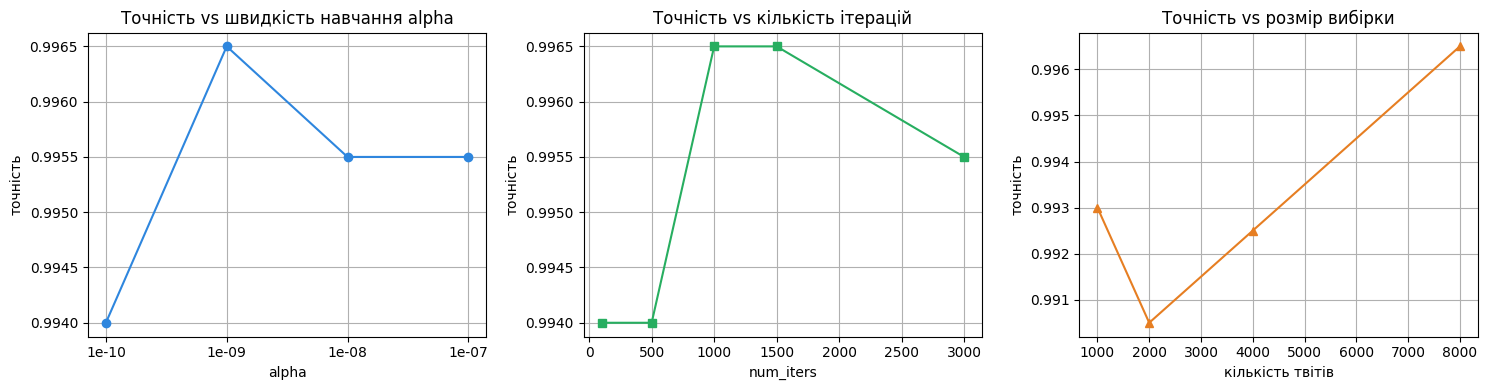

In [12]:
# Крок 7 (п.9, продовження). Візуалізація впливу гіперпараметрів.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].plot([f"{a:.0e}" for a in alphas], acc_alpha, "o-", color="#2E86DE")
ax[0].set_title("Точність vs швидкість навчання alpha")
ax[0].set_xlabel("alpha"); ax[0].set_ylabel("точність"); ax[0].grid(True)

ax[1].plot(iters, acc_iters, "s-", color="#27AE60")
ax[1].set_title("Точність vs кількість ітерацій")
ax[1].set_xlabel("num_iters"); ax[1].set_ylabel("точність"); ax[1].grid(True)

ax[2].plot([2*n for n in sizes], acc_size, "^-", color="#E67E22")
ax[2].set_title("Точність vs розмір вибірки")
ax[2].set_xlabel("кількість твітів"); ax[2].set_ylabel("точність"); ax[2].grid(True)

plt.tight_layout()
plt.show()